<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/6_Xmon_Quantum_Metal_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# Six-Xmon Quantum Processor

Quantum Metal builds two columns of three Xmon qubits on a 5 × 5 mm chip, in which a central coplanar waveguide (CPW) feedline addresses six readout resonators through native `CoupledLineTee` components. Each `RouteMeander` joins a shorted coupler arm to the qubit claw, and the combined transmission-line length follows the specified quarter-wave model.

## Layout parameters

| Parameter | Value or Quantum Metal option |
| --- | --- |
| Chip X size (`CHIP_SIZE_X`) | 5 mm |
| Chip Y size (`CHIP_SIZE_Y`) | 5 mm |
| Qubit columns | $x=-1700$ µm and $x=1700$ µm |
| Qubit rows, top to bottom | $y=1500,0,-1500$ µm |
| Qubit names and frequency order | `Q1_L`, `Q2_L`, `Q3_L`, `Q1_R`, `Q2_R`, `Q3_R` |
| Readout targets | 6.116, 6.353, 6.472, 6.568, 6.655, 6.704 GHz |
| Xmon geometry | `cross_length=260um`, `cross_width=35um`, `cross_gap=20um` |
| Qubit and coupler orientations | Left: −90°; right: +90° |
| Readout claw | Length 190 µm, width 10 µm, gap 6 µm, ground spacing 5 µm |
| Claw CPW extension | Length 60 µm, width 10 µm |
| Josephson inductance | 15.903982052718824 nH, as component metadata |
| Feedline | Width 11.7 µm, gap 5.1 µm |
| Resonator | Width 10 µm, gap 6 µm, circular fillet radius 70 µm |
| Resonator leads | Coupler end: 180 µm; qubit end: 140 µm |
| Native meander spacing | 240 µm |
| Meander asymmetries in frequency order | −90, +90, −90, +90, −90, +90 µm |
| Coupler | Length 200 µm, secondary exit length 110 µm, circular fillet radius 25 µm, shorted termination |
| Coupler ground strip | `coupling_space=4um`, between the two CPW gap boundaries |
| Feedline-to-resonator metal edge separation | $5.1+4+6=15.1$ µm |
| Feedline launchpad pins | $x=0$, $y=pm2000$ µm; complete clearances lie inside the die |
| Launchpad geometry | Width 160 µm, body length 200 µm, taper 200 µm, lead 25 µm, gap 58 µm |
| GDS layer 3 | Positive ground and readout metal |
| GDS layer 9 | Six 35 × 20 µm symbolic lumped-junction markers |
| Ground-plane cheesing | Native layer-3 grid: 25 × 25 µm square holes, 100 µm center-to-center pitch |
| Cheese keep-out | Native 25 µm component buffer; hole boundaries stay at least 100 µm inside every chip edge |
| GDS precision | 1 nm |

The assumed phase velocity $v_p=1.20\times10^8$ m/s sets the total resonator length $\ell$ for each target frequency $f_r$, in the uniform transmission-line limit with an open qubit-facing end and a shorted coupler end.

$$
\ell=\frac{v_p}{4f_r}=\ell_{\mathrm{meander}}+\ell_{\mathrm{coupler}},\qquad f_r\propto\ell^{-1}.
$$

`RouteMeander.length` includes its circular bends, and the coupler contribution includes the same circular-bend correction; the displayed frequency column evaluates this length model, while an electromagnetic solve determines the loaded resonances. Layer 9 holds symbolic junction sheets.

## API documentation

[Quantum Metal installation](https://qiskit-community.github.io/qiskit-metal/installation.html) · [Transmon cross geometry](https://qiskit-community.github.io/qiskit-metal/circuit-examples/A.Qubits/01-Transmon_cross.html) · [Native meander routing](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.12-Simple-Meander.html) · [Coupled-line tee options](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.CoupledLineTee.html) · [Built-in cheesing and keep-out options](https://qiskit-community.github.io/qiskit-metal/tut/3-Renderers/3.2-Export-your-design-to-GDS.html)

In [9]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip install -q quantum-metal

In [10]:
"""This script builds a six-Xmon processor in Quantum Metal."""

# --- Control Knobs ---
CHIP_SIZE_X = "5mm"
CHIP_SIZE_Y = "5mm"
QUBIT_X_UM = 1700.0
ROW_Y_UM = (1500.0, 0.0, -1500.0)
READOUT_FREQUENCIES_GHZ = (6.116, 6.353, 6.472, 6.568, 6.655, 6.704)
PHASE_VELOCITY_M_S = 1.20e8
METAL_LAYER = 3
JUNCTION_MARKER_LAYER = 9
OUTPUT_FILENAME = "6_Xmon_Qubits.gds"

# --- Imports and Design ---
import logging
import os
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

import gdstk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit_metal as qm
from IPython.display import FileLink, display
from matplotlib.collections import PolyCollection
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.qubits.transmon_cross import TransmonCross
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer

plt.rcParams["figure.dpi"] = 250

assert len(READOUT_FREQUENCIES_GHZ) == 2 * len(ROW_Y_UM)
assert METAL_LAYER != JUNCTION_MARKER_LAYER
design = designs.DesignPlanar(overwrite_enabled=True, enable_renderers=False)
design.chips.main.size.size_x = CHIP_SIZE_X
design.chips.main.size.size_y = CHIP_SIZE_Y
design.variables.cpw_width = "10um"
design.variables.cpw_gap = "6um"
gds_renderer = QGDSRenderer(design)
design.renderers.gds = gds_renderer
qubits, couplers, resonators, launchpads = [], [], [], []
sites, length_records = [], []
print(f"Quantum Metal {version('quantum-metal')}")

Quantum Metal 0.9.0


In [11]:
# --- Feedline and Wirebond Launchpads ---
for name, y_um, angle in (("wb_top", 2000, -90), ("wb_bottom", -2000, 90)):
    launchpads.append(LaunchpadWirebond(
        design, name,
        options=Dict(
            pos_x="0um", pos_y=f"{y_um}um", orientation=str(angle),
            layer=str(METAL_LAYER), trace_width="11.7um", trace_gap="5.1um",
            lead_length="25um", pad_width="160um", pad_height="200um",
            pad_gap="58um", taper_height="200um",
        ),
    ))

feedline = RouteStraight(
    design, "feedline",
    options=Dict(
        layer=str(METAL_LAYER), trace_width="11.7um", trace_gap="5.1um",
        pin_inputs=Dict(
            start_pin=Dict(component="wb_top", pin="tie"),
            end_pin=Dict(component="wb_bottom", pin="tie"),
        ),
    ),
)

# --- Qubits, Native Couplers, and Meanders ---
for side, x_um, angle, asymmetries in (
    ("L", -QUBIT_X_UM, -90, (-90, 90, -90)),
    ("R", QUBIT_X_UM, 90, (90, -90, 90)),
):
    for row, (y_um, asymmetry_um) in enumerate(zip(ROW_Y_UM, asymmetries)):
        name = f"Q{row + 1}_{side}"
        frequency_ghz = READOUT_FREQUENCIES_GHZ[len(sites)]
        qubit = TransmonCross(
            design, name,
            options=Dict(
                pos_x=f"{x_um}um", pos_y=f"{y_um}um",
                orientation=str(angle), layer=str(METAL_LAYER),
                cross_length="260um", cross_width="35um", cross_gap="20um",
                connection_pads=Dict(c=Dict(
                    connector_location="90", connector_type="0",
                    claw_length="190um", claw_width="10um", claw_gap="6um",
                    claw_cpw_length="60um", claw_cpw_width="10um",
                    ground_spacing="5um",
                )),
                hfss_inductance="15.903982052718824nH",
                aedt_hfss_inductance="15.903982052718824nH",
            ),
        )
        coupler = CoupledLineTee(
            design, f"clt_{name}",
            options=Dict(
                pos_x="0um", pos_y=f"{y_um}um", orientation=str(angle),
                layer=str(METAL_LAYER), prime_width="11.7um", prime_gap="5.1um",
                second_width="10um", second_gap="6um",
                coupling_length="200um", coupling_space="4um",
                down_length="110um", fillet="25um", open_termination=False,
            ),
        )
        target_mm = PHASE_VELOCITY_M_S / (4 * frequency_ghz * 1e9) * 1e3
        secondary = coupler.qgeometry_table("path")
        secondary = secondary[secondary.name == "second_cpw"].iloc[0]
        coupler_mm = (
            secondary.geometry.length
            - (2 - np.pi / 2) * float(secondary.fillet)
        )
        resonator = RouteMeander(
            design, f"rr_{name}",
            options=Dict(
                layer=str(METAL_LAYER), trace_width="10um", trace_gap="6um",
                pin_inputs=Dict(
                    start_pin=Dict(component=coupler.name, pin="second_end"),
                    end_pin=Dict(component=qubit.name, pin="c"),
                ),
                total_length=f"{target_mm - coupler_mm:.12f}mm",
                fillet="70um",
                lead=Dict(start_straight="180um", end_straight="140um"),
                meander=Dict(spacing="240um", asymmetry=f"{asymmetry_um}um"),
                prevent_short_edges="true",
            ),
        )
        actual_mm = resonator.length + coupler_mm
        qubits.append(qubit)
        couplers.append(coupler)
        resonators.append(resonator)
        sites.append(Dict(name=name, x_um=x_um, y_um=y_um))
        length_records.append({
            "qubit": name, "target_GHz": frequency_ghz,
            "target_um": target_mm * 1000,
            "meander_um": resonator.length * 1000,
            "coupler_um": coupler_mm * 1000,
            "total_um": actual_mm * 1000,
            "error_um": (actual_mm - target_mm) * 1000,
            "length_model_GHz": PHASE_VELOCITY_M_S / (4 * actual_mm * 1e6),
        })

# --- Junction Markers ---
junction_table = design.qgeometry.tables["junction"].copy(deep=True)
for _, junction in junction_table.iterrows():
    owner = design._components[int(junction.component)]
    owner.add_qgeometry(
        "poly", {"junction_marker": junction.geometry.buffer(
            float(junction.width) / 2, cap_style=2,
        )}, layer=JUNCTION_MARKER_LAYER,
    )

# --- Geometry and Length Checks ---
length_table = pd.DataFrame(length_records)
assert length_table.error_um.abs().max() < 0.01
chip_bounds, chip_status = design.get_x_y_for_chip("main")
assert chip_status == 0
for component in design.components.values():
    assert component.status == "good", component.name
    xmin, ymin, xmax, ymax = component.qgeometry_bounds()
    assert xmin >= chip_bounds[0] and ymin >= chip_bounds[1], component.name
    assert xmax <= chip_bounds[2] and ymax <= chip_bounds[3], component.name
for table_name in ("poly", "path"):
    table = design.qgeometry.tables[table_name]
    assert table.geometry.is_valid.all(), table_name
    assert not table.geometry.is_empty.any(), table_name
display(length_table.round(4))
print(f"{len(qubits)} Xmon qubits; {len(resonators)} resonators; "
      f"{len(launchpads)} launchpads")

  self.tables[kind] = pd.concat(



,qubit,target_GHz,target_um,meander_um,coupler_um,total_um,error_um,length_model_GHz
0,Q1_L,6.116,4905.1668,4605.8969,299.2699,4905.1668,0.0,6.116
1,Q2_L,6.353,4722.1785,4422.9086,299.2699,4722.1785,-0.0,6.353
2,Q3_L,6.472,4635.3523,4336.0824,299.2699,4635.3523,0.0,6.472
3,Q1_R,6.568,4567.6005,4268.3306,299.2699,4567.6005,0.0,6.568
4,Q2_R,6.655,4507.8888,4208.6189,299.2699,4507.8888,0.0,6.655
5,Q3_R,6.704,4474.9403,4175.6704,299.2699,4474.9403,-0.0,6.704


6 Xmon qubits; 6 resonators; 2 launchpads


  geopandas.GeoDataFrame(pd.concat(copy_subtract, ignore_index=False))

  geopandas.GeoDataFrame(pd.concat(copy_no_subtract, ignore_index=False))



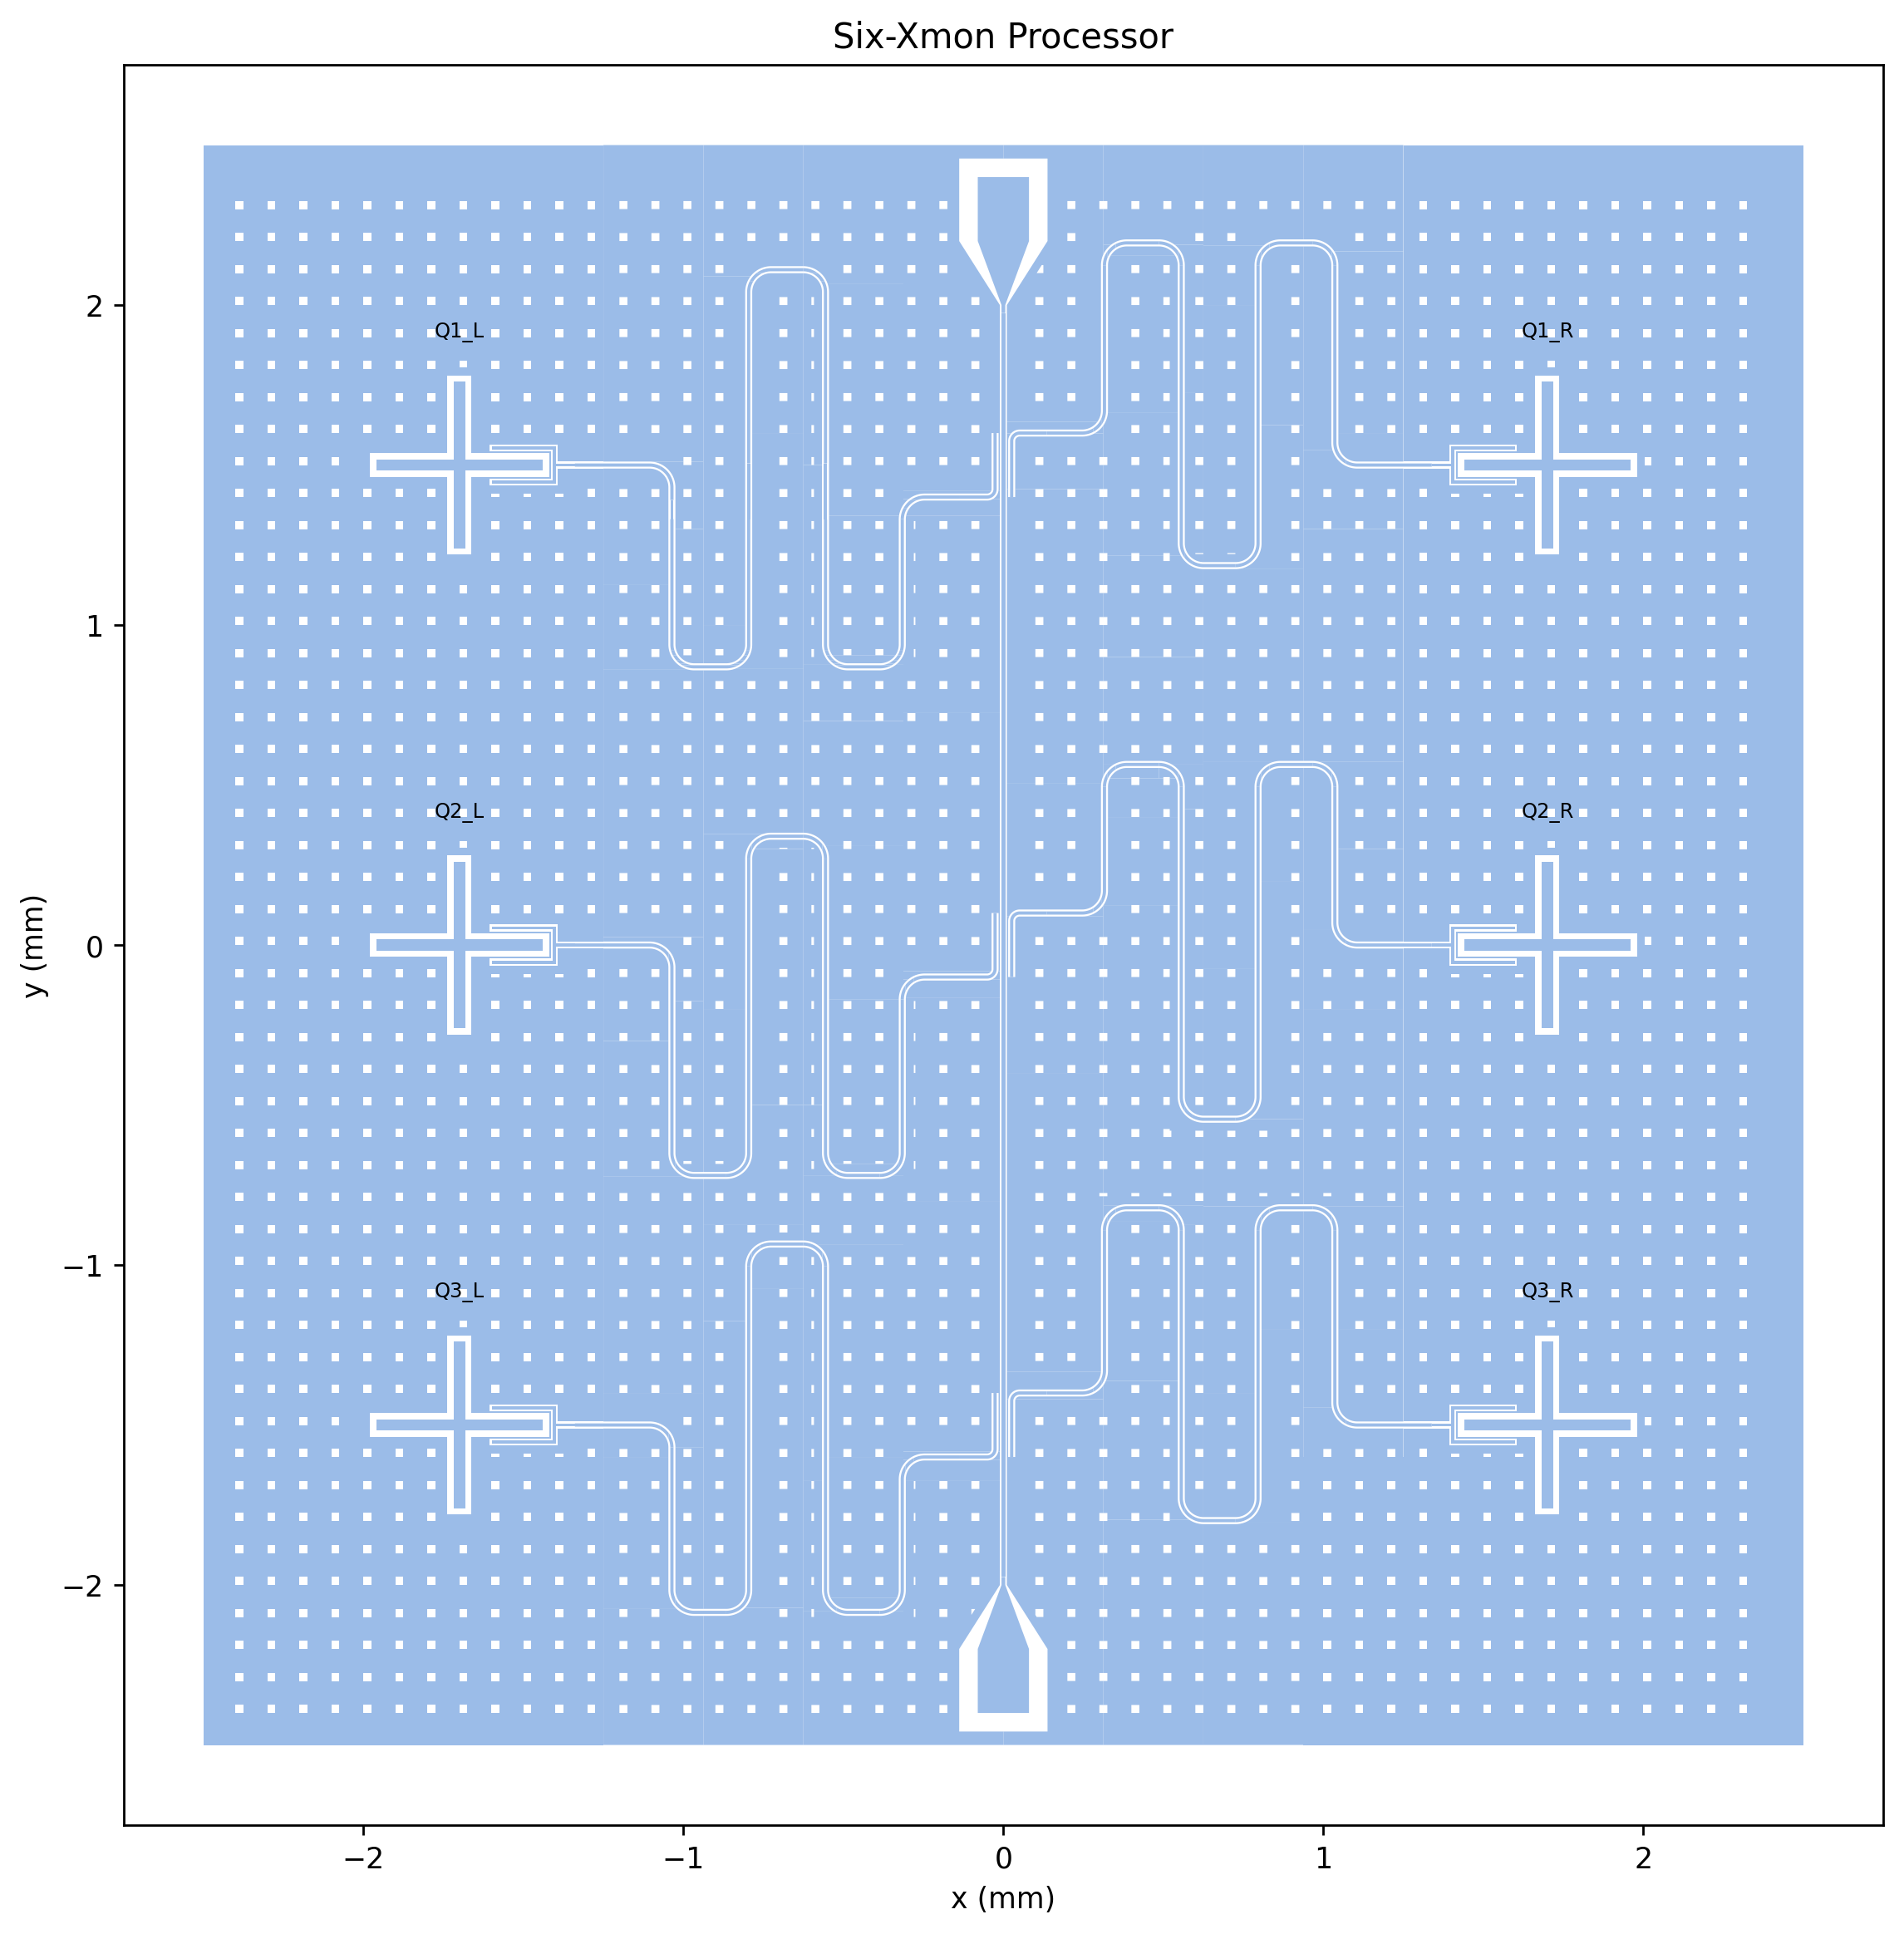

GDSII: 6_Xmon_Qubits.gds (369,834 bytes)
Layers: 3 = ground/readout metal; 9 = junction markers


/content/6_Xmon_Qubits.gds

In [12]:
# --- Native Cheesing and GDS Export ---
out = Path.cwd() / OUTPUT_FILENAME
gds_renderer.options.precision = "1e-9"
gds_renderer.options.tolerance = "1e-6"
gds_renderer.options.fabricate = "True"
gds_renderer.options.short_segments_to_not_fillet = "False"
gds_renderer.options.path_filename = ""

# Restore Quantum Metal defaults before enabling the metal layer.
gds_renderer.options.cheese = QGDSRenderer.default_options.cheese.copy()
# Hole-center inset = 100 um edge clearance + half the 25 um hole width.
gds_renderer.options.cheese.edge_nocheese = "112.5um"
gds_renderer.options.cheese.view_in_file = Dict(main={
    METAL_LAYER: True, JUNCTION_MARKER_LAYER: False,
})
gds_renderer.options.no_cheese.view_in_file = Dict(main={
    METAL_LAYER: False, JUNCTION_MARKER_LAYER: False,
})

# Junction sheets already appear as layer-9 marker polygons.
design.qgeometry.tables["junction"] = junction_table.iloc[:0].copy()
previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    export_status = gds_renderer.export_to_gds(str(out))
finally:
    qm.logger.setLevel(previous_log_level)
    design.qgeometry.tables["junction"] = junction_table
assert export_status and out.is_file() and out.stat().st_size > 0

# Keep references only to cells present in the exported library.
cell_names = {cell.name for cell in gds_renderer.lib.cells}
for cell in gds_renderer.lib.cells:
    for reference in list(cell.references):
        if reference.cell_name not in cell_names:
            cell.remove(reference)
gds_renderer.lib.write_gds(str(out))

# --- Export Checks ---
verified_gds = gdstk.read_gds(str(out))
top_cells = verified_gds.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {polygon.layer for polygon in exported_polygons} == {
    METAL_LAYER, JUNCTION_MARKER_LAYER,
}
assert np.isclose(verified_gds.precision, 1e-9)
assert sum(polygon.layer == JUNCTION_MARKER_LAYER
           for polygon in exported_polygons) == len(qubits)

# --- In-Memory GDS Preview ---
fig, ax = plt.subplots(figsize=(11, 11), dpi=250)
ax.add_collection(PolyCollection(
    [polygon.points for polygon in exported_polygons
     if polygon.layer == METAL_LAYER],
    facecolor="#9bbce8", edgecolor="none", rasterized=True,
))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set(xlabel="x (mm)", ylabel="y (mm)", title="Six-Xmon Processor")
for site in sites:
    ax.text(site.x_um / 1000, site.y_um / 1000 + 0.4, site.name,
            ha="center", fontsize=7, fontfamily="DejaVu Sans", weight="normal")
plt.show()

print(f"GDSII: {out.name} ({out.stat().st_size:,} bytes)")
print("Layers: 3 = ground/readout metal; 9 = junction markers")
display(FileLink(str(out)))